<a href="https://colab.research.google.com/github/daniafzc/tugas3pcd/blob/main/tugaspcd3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image   # only to open the file

img = np.array(Image.open("rice.jpg").convert("RGB"))
print(img.shape)

(960, 960, 3)


In [ ]:
gray = (0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]).round().astype(np.uint8)
print(gray.shape, gray.min(), gray.max())

(960, 960) 4 248


## 2. Segmentation: Otsu

threshold: 156 | foreground pixels: 154936


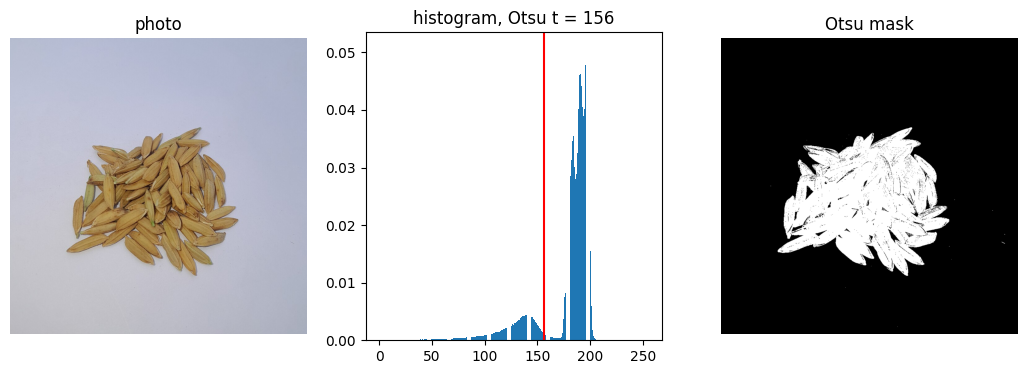

In [ ]:
def otsu(g):
    p = np.bincount(g.ravel(), minlength=256) / g.size
    w0 = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    ok = (w0 > 0) & (w0 < 1)
    var = np.zeros(256)
    var[ok] = (mu[-1] * w0[ok] - mu[ok]) ** 2 / (w0[ok] * (1 - w0[ok]))
    return int(var.argmax()), p


t, p = otsu(gray)
mask = gray <= t        # the grains are darker than the background
print("threshold:", t, "| foreground pixels:", mask.sum())

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(img); ax[0].set_title("photo"); ax[0].axis("off")
ax[1].bar(range(256), p); ax[1].axvline(t, color="r"); ax[1].set_title(f"histogram, Otsu t = {t}")
ax[2].imshow(mask, cmap="gray"); ax[2].set_title("Otsu mask"); ax[2].axis("off")
plt.show()

## 3. Morphological Operations

In [ ]:
def disk(r):
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x * x + y * y <= r * r

def erode(m, se):
    r = se.shape[0] // 2
    pad = np.pad(m, r, constant_values=True)
    out = np.ones_like(m)
    for dy in range(se.shape[0]):
        for dx in range(se.shape[1]):
            if se[dy, dx]:
                out &= pad[dy:dy + m.shape[0], dx:dx + m.shape[1]]
    return out

def dilate(m, se):
    r = se.shape[0] // 2
    pad = np.pad(m, r, constant_values=False)
    out = np.zeros_like(m)
    for dy in range(se.shape[0]):
        for dx in range(se.shape[1]):
            if se[dy, dx]:
                out |= pad[dy:dy + m.shape[0], dx:dx + m.shape[1]]
    return out

def opening(m, se):
    return dilate(erode(m, se), se)

def closing(m, se):
    return erode(dilate(m, se), se)

# tiny check: a 5x5 square eroded by 3x3 should be 3x3 = 9 px, dilated 7x7 = 49 px
sq = np.zeros((9, 9), bool)
sq[2:7, 2:7] = True
print(erode(sq, np.ones((3, 3), bool)).sum(), dilate(sq, np.ones((3, 3), bool)).sum())

9 49


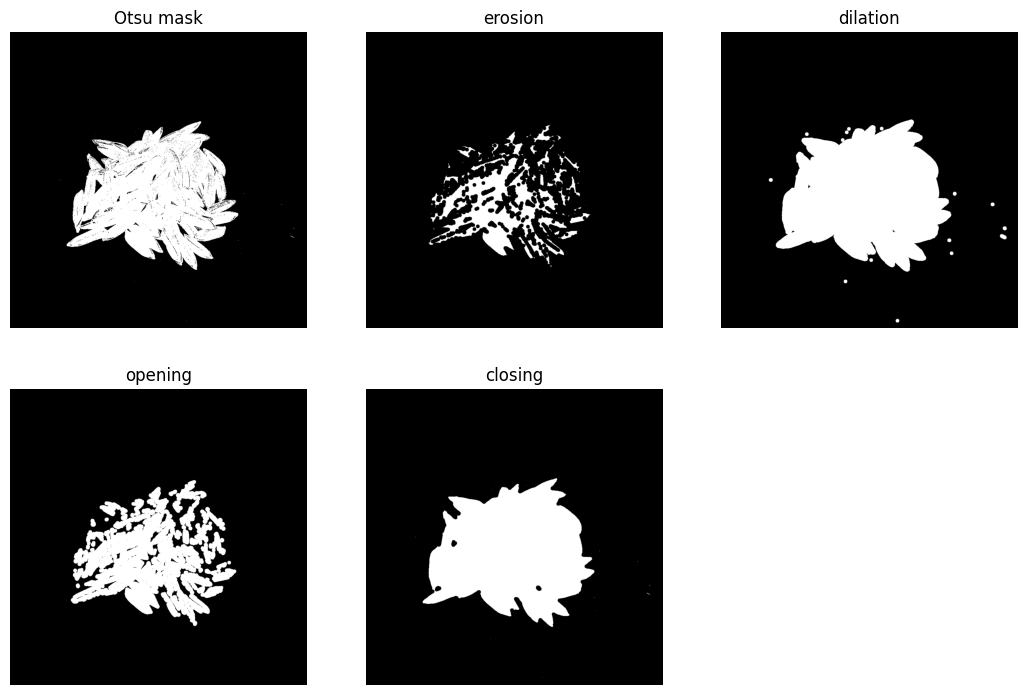

In [ ]:
se = disk(6)
steps = [("Otsu mask", mask), ("erosion", erode(mask, se)), ("dilation", dilate(mask, se)),
         ("opening", opening(mask, se)), ("closing", closing(mask, se))]

fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
axes = ax.flatten()
axes[5].axis('off')
for a, (name, m) in zip(ax.ravel(), steps):
    a.imshow(m, cmap="gray"); a.set_title(name); a.axis("off")
plt.show()

## 4. With vs Without Morphological Operations

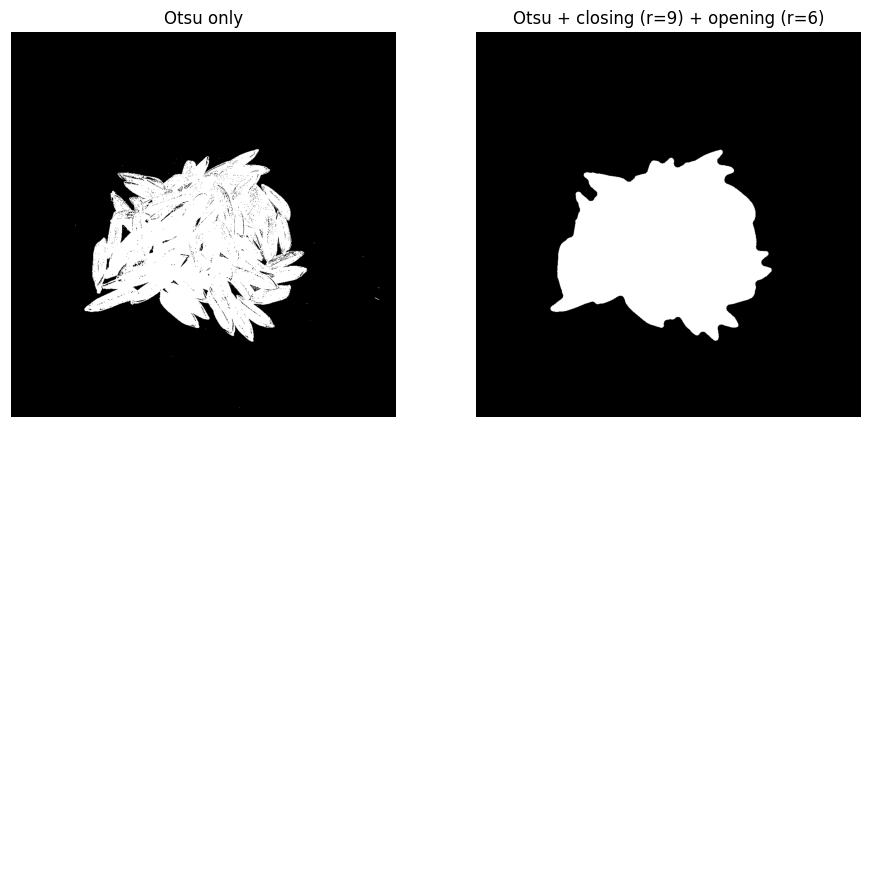

In [ ]:
clean = opening(closing(mask, disk(9)), disk(6))

fig, ax = plt.subplots(2, 2, figsize=(11, 11))
ax[0, 0].imshow(mask, cmap="gray"); ax[0, 0].set_title("Otsu only")
ax[0, 1].imshow(clean, cmap="gray"); ax[0, 1].set_title("Otsu + closing (r=9) + opening (r=6)")
for a in ax.ravel():
    a.axis("off")
plt.show()

In [ ]:
alt = closing(opening(mask, disk(6)), disk(9))   # urutan sebaliknya
print("Otsu saja      :", mask.sum())
print("closing->opening:", clean.sum(), f"({(clean.sum()/mask.sum()-1)*100:.1f}%)")
print("opening->closing:", alt.sum())

Otsu saja      : 154936
closing->opening: 167991 (8.4%)
opening->closing: 141143
